In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
df = pd.read_csv("american_bankruptcy_dataset.csv")

display(df.head())

,company_name,fyear,status_label,X1,X2,X3,X4,X5,X6,X7,...,X11,X12,X13,X14,X15,X16,X17,X18,Division,MajorGroup
0,C_1,1999.0,alive,511267.0,740998.000,833107.0,180447.0,18373.00,70658.00,89031.000,...,35.163,201026.000,128.348,1024333.000,372.7519,401483.0,1024333.000,935302.0,D,37
1,C_1,2000.0,alive,485856.0,701.854,713811.0,179987.0,18577.00,45.79,64367.000,...,18531.000,204065.000,115187.000,874255.000,377.1180,361642.0,874255.000,809888.0,D,37
2,C_1,2001.0,alive,436656.0,710199.000,526477.0,217699.0,22496.00,4711.00,27207.000,...,-58.939,139.603,77528.000,638721.000,364.5928,399964.0,638721.000,611514.0,D,37
3,C_1,2002.0,alive,396412.0,686.621,496747.0,164658.0,27172.00,3573.00,30745.000,...,-12.410,124106.000,66322.000,606337.000,143.3295,391633.0,606337.000,575592.0,D,37
4,C_1,2003.0,alive,432204.0,709.292,523302.0,248666.0,26.68,20811.00,47.491,...,3504.000,131884.000,104661.000,651.958,308.9071,407608.0,651.958,604467.0,D,37


## 1.1. Podstawowe informacje o zbiorze danych

W analizie wykorzystano American Bankruptcy Dataset, obejmujący
historyczne dane finansowe amerykańskich przedsiębiorstw giełdowych
z lat 1999–2018.

Celem analizy jest poznanie struktury zbioru, sprawdzenie jakości danych
oraz identyfikacja cech, które mogą być przydatne do przewidywania
bankructwa przedsiębiorstw.

In [6]:
print("Liczba obserwacji:", df.shape[0])
print("Liczba kolumn:", df.shape[1])
print("Liczba przedsiębiorstw:", df["company_name"].nunique())

print("\nNazwy kolumn:")
print(df.columns.tolist())

print("\nTypy danych:")
df.info()

Liczba obserwacji: 78682
Liczba kolumn: 23
Liczba przedsiębiorstw: 8971

Nazwy kolumn:
['company_name', 'fyear', 'status_label', 'X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8', 'X9', 'X10', 'X11', 'X12', 'X13', 'X14', 'X15', 'X16', 'X17', 'X18', 'Division', 'MajorGroup']

Typy danych:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 78682 entries, 0 to 78681
Data columns (total 23 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   company_name  78682 non-null  object 
 1   fyear         78682 non-null  float64
 2   status_label  78682 non-null  object 
 3   X1            78682 non-null  float64
 4   X2            78682 non-null  float64
 5   X3            78682 non-null  float64
 6   X4            78682 non-null  float64
 7   X5            78682 non-null  float64
 8   X6            78682 non-null  float64
 9   X7            78682 non-null  float64
 10  X8            78682 non-null  float64
 11  X9            78682 non-null  float64
 12

## 1.2. Kontrola jakości danych

Przed rozpoczęciem modelowania sprawdzono występowanie brakujących
wartości, zduplikowanych obserwacji oraz wartości nieskończonych.

Kontrola jakości danych pozwala ustalić, czy konieczne jest ich
dodatkowe czyszczenie.

In [7]:
print("Łączna liczba braków:", df.isna().sum().sum())

print("Liczba duplikatów wierszy:", df.duplicated().sum())

print(
    "Duplikaty przedsiębiorstwo-rok:",
    df.duplicated(subset=["company_name", "fyear"]).sum()
)

kolumny_liczbowe = df.select_dtypes(include="number")

print(
    "Liczba wartości nieskończonych:",
    np.isinf(kolumny_liczbowe).sum().sum()
)

display(df.isna().sum().to_frame("Liczba braków"))

Łączna liczba braków: 0
Liczba duplikatów wierszy: 0
Duplikaty przedsiębiorstwo-rok: 0
Liczba wartości nieskończonych: 0


,Liczba braków
company_name,0
fyear,0
status_label,0
X1,0
X2,0
X3,0
X4,0
X5,0
X6,0
X7,0


## 1.3. Rozkład zmiennej celu

Zmienna status_label przyjmuje dwie wartości:

- alive – przedsiębiorstwo bez oznaczonego zdarzenia bankructwa,
- failed – rok finansowy poprzedzający zgłoszenie bankructwa.

Analiza rozkładu klas pozwala określić, czy zbiór jest zrównoważony.

,Liczba obserwacji,Udział (%)
status_label,,
alive,73462,93.37
failed,5220,6.63


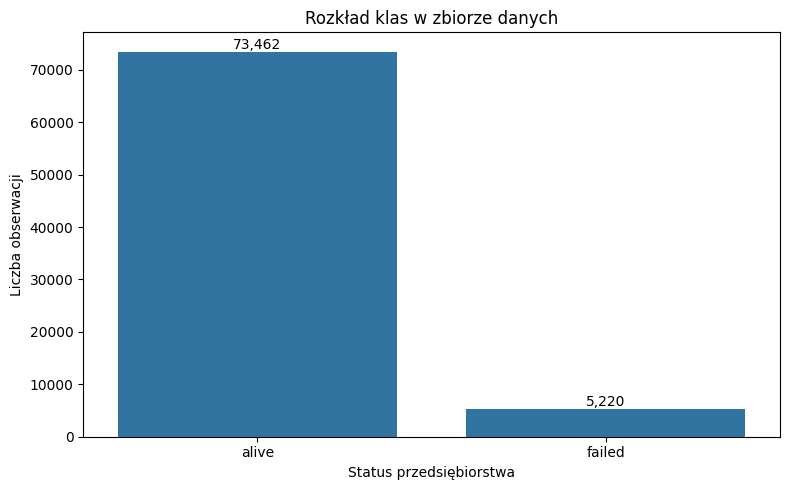

In [9]:
liczebnosci = df["status_label"].value_counts()
procenty = df["status_label"].value_counts(normalize=True) * 100

display(pd.DataFrame({
    "Liczba obserwacji": liczebnosci,
    "Udział (%)": procenty.round(2)
}))

plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x="status_label",
    order=["alive", "failed"]
)

for p in ax.patches:
    ax.annotate(
        f"{int(p.get_height()):,}",
        (p.get_x() + p.get_width()/2, p.get_height()),
        ha="center",
        va="bottom"
    )

plt.title("Rozkład klas w zbiorze danych")
plt.xlabel("Status przedsiębiorstwa")
plt.ylabel("Liczba obserwacji")
plt.tight_layout()
plt.show()